In [2]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torchvision

from torchvision.datasets import MNIST
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors

print("Torchvision version:", torchvision.__version__)

Torchvision version: 0.29.2+cpu


In [3]:
# Tải training set: 60.000 ảnh
train_dataset = MNIST(
    root="../MNIST",
    train=True,
    download=True
)

# Tải test set: 10.000 ảnh
test_dataset = MNIST(
    root="../MNIST",
    train=False,
    download=True
)

# Tách riêng train và test, không ghép chung
X_train = train_dataset.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
y_train = train_dataset.targets.numpy()

X_test = test_dataset.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
y_test = test_dataset.targets.numpy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (60000, 784)
y_train: (60000,)
X_test: (10000, 784)
y_test: (10000,)


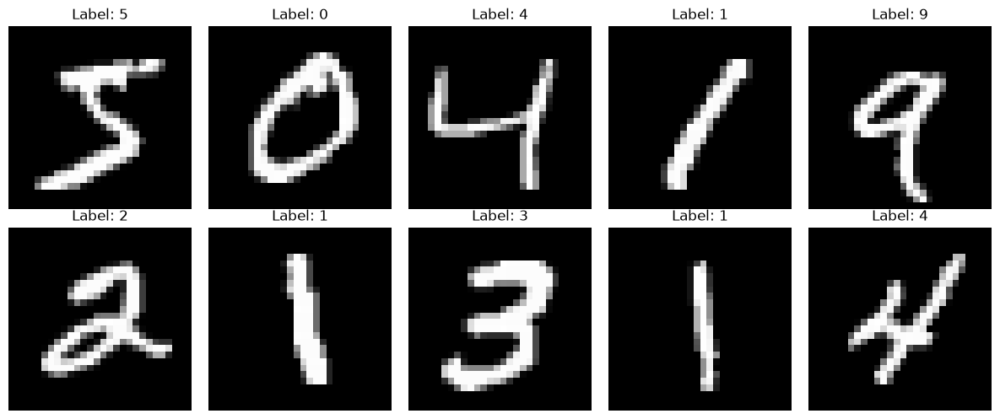

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
K = 10

kmeans = KMeans(
    n_clusters=K,
    random_state=42,
    n_init=10
)

kmeans.fit(X_train)                 # Chỉ train trên tập train
train_clusters = kmeans.labels_
test_clusters = kmeans.predict(X_test)  # Dùng mô hình để phân cụm test

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Train clusters shape:", train_clusters.shape)
print("Test clusters shape:", test_clusters.shape)
print("Cluster centers shape:", kmeans.cluster_centers_.shape)

X_train shape: (60000, 784)
X_test shape: (10000, 784)
Train clusters shape: (60000,)
Test clusters shape: (10000,)
Cluster centers shape: (10, 784)


In [6]:
# Loss trên train: tổng bình phương khoảng cách tới tâm cụm
train_loss = kmeans.inertia_

# Loss trên test: dùng các cụm đã dự đoán và tâm cụm đã học từ train
test_distances = kmeans.transform(X_test)
test_loss = np.sum(np.min(test_distances, axis=1) ** 2)

print("Train loss (inertia):", train_loss)
print("Test loss:", test_loss)
print("Train loss trung bình mỗi ảnh:", train_loss / len(X_train))
print("Test loss trung bình mỗi ảnh:", test_loss / len(X_test))

Train loss (inertia): 2352825.5
Test loss: 392324.06
Train loss trung bình mỗi ảnh: 39.21375833333333
Test loss trung bình mỗi ảnh: 39.232407


In [7]:
import pandas as pd

# Cluster do KMeans gán cho từng mẫu train
y_train_cluster = kmeans.predict(X_train)

# Ánh xạ mỗi cluster sang nhãn thật xuất hiện nhiều nhất trong cluster đó
cluster_to_label = (
    pd.crosstab(y_train_cluster, y_train)
    .idxmax(axis=1)
    .to_dict()
)

In [8]:
import numpy as np
import pandas as pd

# X_test cần được xử lý giống dữ liệu khi huấn luyện
y_pred_test = kmeans.predict(X_test)

# Sau đó mới chạy cell ánh xạ và so sánh nhãn
y_pred_test_mapped = np.array([
    cluster_to_label[cluster] for cluster in y_pred_test
])

y_true = np.asarray(y_test)
wrong = y_pred_test_mapped != y_true

print(f"Số dự đoán sai: {wrong.sum()}/{len(y_true)}")
print(f"Tỷ lệ sai: {wrong.mean() * 100:.2f}%")


Số dự đoán sai: 4050/10000
Tỷ lệ sai: 40.50%


In [9]:
def display_network(A, m, n):
    """
    A: ma trận (784, số lượng ảnh)
       Mỗi cột là một ảnh.
    m: số hàng ảnh
    n: số cột ảnh
    """

    sz = int(np.sqrt(A.shape[0]))

    if sz * sz != A.shape[0]:
        raise ValueError("Số chiều mỗi ảnh phải là số chính phương")

    img = np.zeros((m * sz, n * sz))

    for i in range(m):
        for j in range(n):
            if i * n + j >= A.shape[1]:
                break

            img[
                i * sz:(i + 1) * sz,
                j * sz:(j + 1) * sz
            ] = A[:, i * n + j].reshape(sz, sz)

    return img

(10, 784)


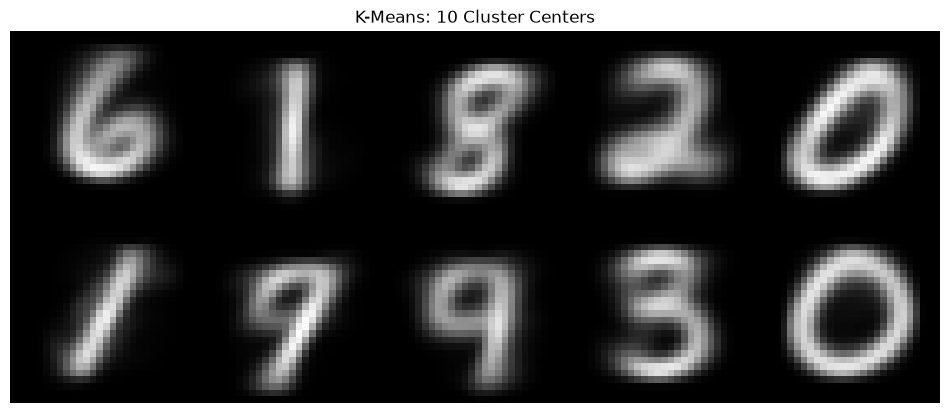

In [10]:
print(kmeans.cluster_centers_.shape)

# Chuyển vị để mỗi cột là một ảnh
centers = kmeans.cluster_centers_.T

A = display_network(centers, 2, 5)

plt.figure(figsize=(12, 5))
plt.imshow(A, cmap="gray")
plt.axis("off")
plt.title("K-Means: 10 Cluster Centers")
plt.show()

In [11]:
N0 = 20

X1 = np.zeros((N0 * K, 784), dtype=np.float32)
X2 = np.zeros((N0 * K, 784), dtype=np.float32)

for k in range(K):

    # Lấy các ảnh test được gán vào cluster k
    Xk = X_test[test_clusters == k, :]

    print(f"Cluster {k}: {len(Xk)} test images")

    # Lấy centroid đã học từ tập train
    center_k = kmeans.cluster_centers_[k].reshape(1, -1)

    # Tìm 20 ảnh test gần centroid nhất
    neigh = NearestNeighbors(n_neighbors=N0).fit(Xk)

    dist, nearest_id = neigh.kneighbors(center_k)

    # Lưu 20 ảnh test gần centroid nhất
    X1[N0*k:N0*(k+1), :] = Xk[nearest_id[0], :]

    # Lưu 20 ảnh test đầu tiên trong cluster
    X2[N0*k:N0*(k+1), :] = Xk[:N0, :]

Cluster 0: 929 test images
Cluster 1: 995 test images
Cluster 2: 1094 test images
Cluster 3: 799 test images
Cluster 4: 548 test images
Cluster 5: 847 test images
Cluster 6: 1428 test images
Cluster 7: 1550 test images
Cluster 8: 1315 test images
Cluster 9: 495 test images


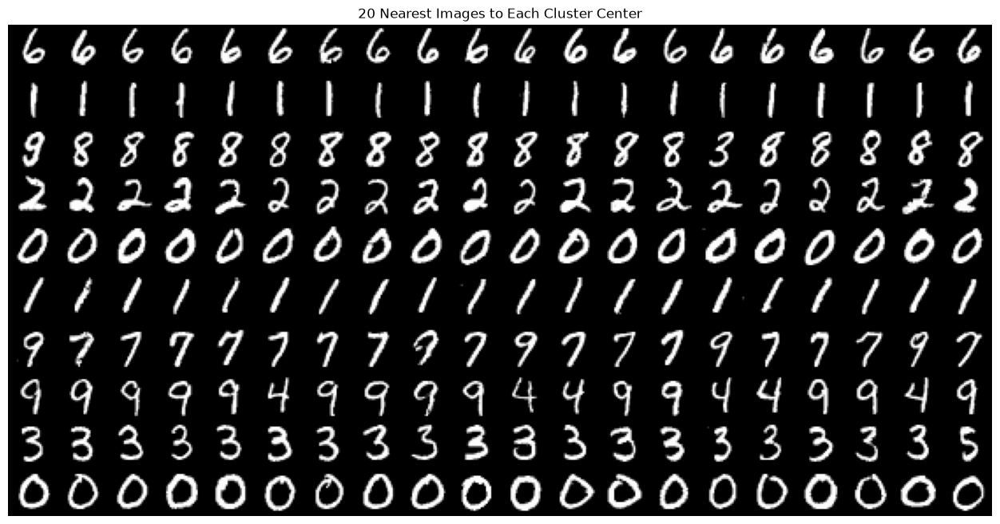

In [12]:
A = display_network(X1.T, K, N0)

plt.figure(figsize=(16, 8))
plt.imshow(A, cmap="gray")
plt.axis("off")
plt.title("20 Nearest Images to Each Cluster Center")
plt.show()

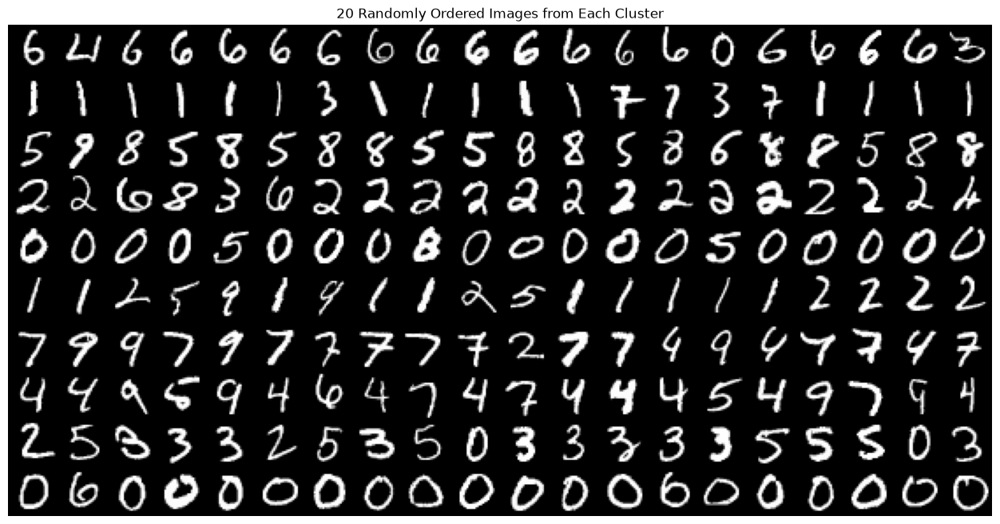

In [13]:
A = display_network(X2.T, K, N0)

plt.figure(figsize=(16, 8))
plt.imshow(A, cmap="gray")
plt.axis("off")
plt.title("20 Randomly Ordered Images from Each Cluster")
plt.show()

In [14]:
cluster_to_digit = np.empty(K, dtype=np.int64)

for k in range(K):
    # Gán tên cho mỗi cụm chỉ từ nhãn của tập train
    train_labels = y_train[train_clusters == k]
    train_counts = np.bincount(train_labels, minlength=10)
    cluster_to_digit[k] = np.argmax(train_counts)

    # Dùng nhãn test để kiểm định, không dùng để tạo ánh xạ cụm
    test_labels = y_test[test_clusters == k]
    test_counts = np.bincount(test_labels, minlength=10)

    print(f"\nCluster {k}")
    print("Train digit distribution:", train_counts)
    print("Digit mapped from train:", cluster_to_digit[k])
    print("Test digit distribution:", test_counts)

test_pred_digits = cluster_to_digit[test_clusters]
test_accuracy = np.mean(test_pred_digits == y_test)
print("\nTest accuracy (mapping learned from train):", test_accuracy)


Cluster 0
Train digit distribution: [ 182    9  212   57  165  123 4913    4   47    8]
Digit mapped from train: 6
Test digit distribution: [ 30   2  25   7  36  19 795   1  10   4]

Cluster 1
Train digit distribution: [   3 3717  364  426  159  164  271  327  296  239]
Digit mapped from train: 1
Test digit distribution: [  0 660  59  73  30  23  28  59  34  29]

Cluster 2
Train digit distribution: [ 180   10  158 1039   19 1494   91   10 3456   69]
Digit mapped from train: 8
Test digit distribution: [ 17   1  28 145   4 278  18   1 589  13]

Cluster 3
Train digit distribution: [  17    9 4193  215   38   15   87   38   54   13]
Digit mapped from train: 2
Test digit distribution: [  2   1 707  40   5   4  18  13   6   3]

Cluster 4
Train digit distribution: [2497    0  101  126   11  256  121   15   32   19]
Digit mapped from train: 0
Test digit distribution: [422   0  20  19   1  40  24   1  11  10]

Cluster 5
Train digit distribution: [  21 2977  351  103  309  793  223  282  417  1

In [15]:
from mnist import MNIST

mndata = MNIST(r"D:\DangKhoa\MachineLearning\MNIST", gz=True)
mndata.load_testing()

([[0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0,
   0

In [16]:
import cv2
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

N = 1000
images = np.asarray(mndata.test_images[:N], dtype=np.uint8).reshape(-1, 28, 28)
labels = np.asarray(mndata.test_labels[:N])

def deskew_digit(image):
    _, binary = cv2.threshold(
        image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    moments = cv2.moments(binary)

    if abs(moments["mu02"]) < 1e-2:
        return image

    skew = moments["mu11"] / moments["mu02"]
    matrix = np.float32([
        [1, skew, -0.5 * 28 * skew],
        [0, 1, 0]
    ])
    return cv2.warpAffine(
        image, matrix, (28, 28),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

# KMeans trên ảnh gốc
X_raw = images.reshape(N, 784).astype(np.float32) / 255.0
km_raw = KMeans(n_clusters=10, random_state=42, n_init=5, max_iter=100)
clusters_raw = km_raw.fit_predict(X_raw)

# Deskew toàn bộ ảnh rồi chạy lại KMeans
images_deskewed = np.stack([deskew_digit(img) for img in images])
X_deskewed = images_deskewed.reshape(N, 784).astype(np.float32) / 255.0
km_deskewed = KMeans(n_clusters=10, random_state=42, n_init=5, max_iter=100)
clusters_deskewed = km_deskewed.fit_predict(X_deskewed)

print("Ảnh gốc:    inertia =", km_raw.inertia_,
      "| ARI =", adjusted_rand_score(labels, clusters_raw))
print("Sau deskew: inertia =", km_deskewed.inertia_,
      "| ARI =", adjusted_rand_score(labels, clusters_deskewed))

Ảnh gốc:    inertia = 36586.98046875 | ARI = 0.4199992086941198
Sau deskew: inertia = 36840.33984375 | ARI = 0.25984109102359787


In [17]:
from pathlib import Path
from mnist import MNIST
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import adjusted_rand_score
import cv2
import numpy as np
import pandas as pd

# Thư mục đang chứa các file MNIST .gz
data_dir = Path(r"D:\DangKhoa\MachineLearning\MNIST")
mndata = MNIST(str(data_dir), gz=True)

mndata.load_training()
train_images = np.asarray(mndata.train_images, dtype=np.uint8).reshape(-1, 28, 28)
y_train = np.asarray(mndata.train_labels)

mndata.load_testing()
test_images = np.asarray(mndata.test_images, dtype=np.uint8).reshape(-1, 28, 28)
y_test = np.asarray(mndata.test_labels)

def deskew_digit(image):
    _, binary = cv2.threshold(
        image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    moments = cv2.moments(binary)

    if abs(moments["mu02"]) < 1e-2:
        return image

    skew = moments["mu11"] / moments["mu02"]
    matrix = np.float32([
        [1, skew, -0.5 * 28 * skew],
        [0, 1, 0]
    ])
    return cv2.warpAffine(
        image, matrix, (28, 28),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

def to_features(images):
    return images.reshape(len(images), 784).astype(np.float32) / 255.0

def squared_distance_loss(model, X, chunk_size=4096):
    # Tổng bình phương khoảng cách mỗi ảnh tới tâm cụm gần nhất
    total = 0.0
    for start in range(0, len(X), chunk_size):
        distances = model.transform(X[start:start + chunk_size])
        total += np.square(distances.min(axis=1)).sum()
    return total

def evaluate_pipeline(name, X_train, X_test):
    model = MiniBatchKMeans(
        n_clusters=10,
        random_state=42,
        n_init=3,
        max_iter=100,
        batch_size=1024
    )
    model.fit(X_train)

    train_clusters = model.predict(X_train)
    test_clusters = model.predict(X_test)

    # Đặt tên cụm dựa trên nhãn phổ biến nhất trong TRAIN
    mapping = (
        pd.crosstab(train_clusters, y_train)
        .reindex(index=np.arange(10), columns=np.arange(10), fill_value=0)
        .idxmax(axis=1)
        .to_dict()
    )
    y_pred = np.array([mapping[c] for c in test_clusters])
    wrong = y_pred != y_test

    train_loss = squared_distance_loss(model, X_train)
    test_loss = squared_distance_loss(model, X_test)

    return {
        "Quy trình": name,
        "Train loss (inertia)": train_loss,
        "Train loss / ảnh": train_loss / len(X_train),
        "Test loss": test_loss,
        "Test loss / ảnh": test_loss / len(X_test),
        "Số dự đoán sai": int(wrong.sum()),
        "Tỷ lệ sai (%)": wrong.mean() * 100,
        "ARI": adjusted_rand_score(y_test, test_clusters),
    }

# Dữ liệu gốc
X_train_raw = to_features(train_images)
X_test_raw = to_features(test_images)

# Deskew toàn bộ train và test
train_deskewed = np.stack([deskew_digit(img) for img in train_images])
test_deskewed = np.stack([deskew_digit(img) for img in test_images])
X_train_deskew = to_features(train_deskewed)
X_test_deskew = to_features(test_deskewed)

# Fit và đánh giá hai quy trình
results = [
    evaluate_pipeline("Trước deskew", X_train_raw, X_test_raw),
    evaluate_pipeline("Sau deskew", X_train_deskew, X_test_deskew),
]

display(pd.DataFrame(results).set_index("Quy trình").round(4))

,Train loss (inertia),Train loss / ảnh,Test loss,Test loss / ảnh,Số dự đoán sai,Tỷ lệ sai (%),ARI
Quy trình,,,,,,,
Trước deskew,2374485.25,39.574799,394637.62500,39.463799,4535,45.35,0.3380
Sau deskew,2391618.00,39.860298,399243.65625,39.924400,5787,57.87,0.2003


In [18]:
from sklearn.metrics import confusion_matrix
from scipy.optimize import linear_sum_assignment

# Chỉ chạy nếu các biến dưới đây đã tồn tại từ các cell trước:
# X_train_raw, X_test_raw, y_train, y_test, KMeans

kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
kmeans.fit(X_train_raw)

train_clusters = kmeans.predict(X_train_raw)
test_clusters = kmeans.predict(X_test_raw)

cm = confusion_matrix(train_clusters, y_train, labels=np.arange(10))
cluster_ids, digit_labels = linear_sum_assignment(cm, maximize=True)
mapping = dict(zip(cluster_ids, digit_labels))

y_pred = np.array([mapping[c] for c in test_clusters])
wrong = y_pred != y_test

print("Số dự đoán sai:", wrong.sum())
print("Accuracy:", (1 - wrong.mean()) * 100, "%")

Số dự đoán sai: 4826
Accuracy: 51.74000000000001 %


In [19]:
# Cell 1: load dữ liệu
from torchvision.datasets import MNIST
import numpy as np

train_dataset = MNIST(root="../MNIST", train=True, download=True)
test_dataset = MNIST(root="../MNIST", train=False, download=True)

X_train = train_dataset.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
y_train = train_dataset.targets.numpy()

X_test = test_dataset.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
y_test = test_dataset.targets.numpy()

In [20]:
# Cell 2: KMeans cơ bản
K = 10

kmeans1 = KMeans(n_clusters=K, random_state=42, n_init=10)
train_clusters = kmeans1.fit_predict(X_train)

mixed_clusters = []
for c in range(K):
    labels_in_cluster = y_train[train_clusters == c]
    unique_labels = np.unique(labels_in_cluster)
    if len(unique_labels) > 1:
        mixed_clusters.append(c)

print("Các cluster bị lẫn:", mixed_clusters)

Các cluster bị lẫn: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [21]:
# Cell 3: phân nhỏ các cluster lẫn
cluster_refine_map = {}

for c in mixed_clusters:
    idx = np.where(train_clusters == c)[0]
    X_sub = X_train[idx]
    y_sub = y_train[idx]

    if len(np.unique(y_sub)) > 1:
        n_sub = min(3, len(np.unique(y_sub)))
        kmeans2 = KMeans(n_clusters=n_sub, random_state=42, n_init=10)
        sub_labels = kmeans2.fit_predict(X_sub)

        cluster_refine_map[c] = {
            "model": kmeans2,
            "train_idx": idx,
            "sub_labels": sub_labels
        }

test_clusters = kmeans1.predict(X_test)
y_pred = np.empty(len(X_test), dtype=int)

for c in range(K):
    mask = (test_clusters == c)

    if c in cluster_refine_map:
        model = cluster_refine_map[c]["model"]
        Xc = X_test[mask]
        sub_pred = model.predict(Xc)

        sub_map = {}
        for j in range(model.n_clusters):
            train_idx_j = cluster_refine_map[c]["train_idx"][cluster_refine_map[c]["sub_labels"] == j]
            dominant_digit = np.bincount(y_train[train_idx_j], minlength=10).argmax()
            sub_map[j] = dominant_digit

        y_pred[mask] = np.array([sub_map[j] for j in sub_pred], dtype=int)
    else:
        dominant_digit = np.bincount(y_train[train_clusters == c], minlength=10).argmax()
        y_pred[mask] = dominant_digit

wrong = y_pred != y_test
print("Số dự đoán sai:", wrong.sum())
print("Accuracy:", (1 - wrong.mean()) * 100, "%")

Số dự đoán sai: 3063
Accuracy: 69.37 %


In [22]:
# Sau khi đã có X_train, y_train, và chạy KMeans ban đầu
K = 10

kmeans1 = KMeans(n_clusters=K, random_state=42, n_init=10)
train_clusters = kmeans1.fit_predict(X_train)

# Tạo danh sách các cluster bị lẫn nhãn
mixed_clusters = []

for c in range(K):
    labels_in_cluster = y_train[train_clusters == c]
    unique_labels = np.unique(labels_in_cluster)
    if len(unique_labels) > 1:
        mixed_clusters.append(c)

print("Các cluster bị lẫn:", mixed_clusters)

# Tách tiếp từng cluster lẫn bằng KMeans cấp 2
for c in mixed_clusters:
    idx = np.where(train_clusters == c)[0]
    X_sub = X_train[idx]
    y_sub = y_train[idx]

    # Số sub-cluster tối đa = số nhãn khác nhau trong cluster
    n_sub = min(3, len(np.unique(y_sub)))  # 2 hoặc 3 là đủ cho 4-9 hay 7-8-9

    if n_sub <= 1:
        continue

    kmeans2 = KMeans(n_clusters=n_sub, random_state=42, n_init=10)
    sub_labels = kmeans2.fit_predict(X_sub)

    print(f"\nCluster gốc {c}:")
    for j in range(n_sub):
        sub_idx = idx[sub_labels == j]
        sub_y = y_sub[sub_labels == j]
        print(f"  Sub-cluster {j}: labels =", np.unique(sub_y), "counts =", np.bincount(sub_y, minlength=10)[np.unique(sub_y)])

Các cluster bị lẫn: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Cluster gốc 0:
  Sub-cluster 0: labels = [0 1 2 3 4 5 6 8 9] counts = [  34    3  115   23   74   53 1758    8    1]
  Sub-cluster 1: labels = [0 1 2 3 4 5 6 7 8 9] counts = [  22    1   73    7   17   13 1229    4   10    1]
  Sub-cluster 2: labels = [0 1 2 3 4 5 6 8 9] counts = [ 126    5   24   27   74   57 1926   29    6]

Cluster gốc 1:
  Sub-cluster 0: labels = [1 2 3 4 5 6 7 8 9] counts = [1690   16    3    5    5    1   12    6    4]
  Sub-cluster 1: labels = [0 1 2 3 4 5 6 7 8 9] counts = [  3 113 322 418 147 153 260 276 279 231]
  Sub-cluster 2: labels = [1 2 3 4 5 6 7 8 9] counts = [1914   26    5    7    6   10   39   11    4]

Cluster gốc 2:
  Sub-cluster 0: labels = [0 1 2 3 4 5 6 8 9] counts = [ 143    4   17  748    4 1398   80  158   33]
  Sub-cluster 1: labels = [0 1 2 3 4 5 6 7 8 9] counts = [  26    5   90  202    8   78    9    2 1770   22]
  Sub-cluster 2: labels = [0 1 2 3 4 5 6 7 8 9] counts = [  11    1   51  

In [23]:
# Tách tiếp cluster lẫn cho tập train
cluster_refine_map = {}

for c in mixed_clusters:
    idx = np.where(train_clusters == c)[0]
    X_sub = X_train[idx]
    y_sub = y_train[idx]

    if len(np.unique(y_sub)) > 1:
        n_sub = min(3, len(np.unique(y_sub)))
        kmeans2 = KMeans(n_clusters=n_sub, random_state=42, n_init=10)
        sub_labels = kmeans2.fit_predict(X_sub)

        cluster_refine_map[c] = {
            "model": kmeans2,
            "train_idx": idx,
            "sub_labels": sub_labels
        }

# Dự đoán cho test theo cùng logic
test_clusters = kmeans1.predict(X_test)
y_pred = np.empty(len(X_test), dtype=int)

for c in range(K):
    test_mask = (test_clusters == c)

    if c in cluster_refine_map:
        model = cluster_refine_map[c]["model"]
        Xc = X_test[test_mask]
        sub_pred = model.predict(Xc)

        # Gán mapping cho từng sub-cluster
        sub_map = {}
        for j in range(model.n_clusters):
            train_idx_j = cluster_refine_map[c]["train_idx"][cluster_refine_map[c]["sub_labels"] == j]
            dominant_digit = np.bincount(y_train[train_idx_j], minlength=10).argmax()
            sub_map[j] = dominant_digit

        test_idx = np.where(test_mask)[0]
        for j in range(model.n_clusters):
            idx_j = test_idx[sub_pred == j]
            y_pred[idx_j] = sub_map[j]

    else:
        train_digits = y_train[train_clusters == c]
        dominant_digit = np.bincount(train_digits, minlength=10).argmax()
        y_pred[test_mask] = dominant_digit

print("Done")

Done


In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import confusion_matrix
from scipy.optimize import linear_sum_assignment

def kmeans_loss(model, X):
    distances = model.transform(X)
    return np.square(distances.min(axis=1)).sum()

def evaluate_basic_kmeans(name, X_train, X_test, y_train, y_test, n_clusters=10):
    model = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    train_clusters = model.fit_predict(X_train)
    test_clusters = model.predict(X_test)

    cm = confusion_matrix(train_clusters, y_train, labels=np.arange(n_clusters))
    cluster_ids, digit_labels = linear_sum_assignment(cm, maximize=True)
    mapping = dict(zip(cluster_ids, digit_labels))

    y_pred = np.array([mapping.get(c, 0) for c in test_clusters], dtype=int)
    wrong = y_pred != y_test

    return {
        "Quy trình": name,
        "Train loss (inertia)": model.inertia_,
        "Train loss / ảnh": model.inertia_ / len(X_train),
        "Test loss": kmeans_loss(model, X_test),
        "Test loss / ảnh": kmeans_loss(model, X_test) / len(X_test),
        "Số dự đoán sai": int(wrong.sum()),
        "Tỷ lệ sai (%)": wrong.mean() * 100,
        "ARI": adjusted_rand_score(y_test, test_clusters),
    }

def evaluate_refined_kmeans(name, X_train, X_test, y_train, y_test, n_clusters=10):
    model = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    train_clusters = model.fit_predict(X_train)
    test_clusters = model.predict(X_test)

    cluster_refine_map = {}
    for c in range(n_clusters):
        idx = np.where(train_clusters == c)[0]
        labels_in_cluster = y_train[idx]

        if len(np.unique(labels_in_cluster)) <= 1:
            continue

        n_sub = min(3, len(np.unique(labels_in_cluster)))
        km2 = KMeans(n_clusters=n_sub, random_state=42, n_init=10)
        sub_labels = km2.fit_predict(X_train[idx])

        cluster_refine_map[c] = {
            "model": km2,
            "train_idx": idx,
            "sub_labels": sub_labels
        }

    y_pred = np.empty(len(X_test), dtype=int)

    for c in range(n_clusters):
        mask = (test_clusters == c)

        if c in cluster_refine_map:
            km2 = cluster_refine_map[c]["model"]
            sub_pred = km2.predict(X_test[mask])

            sub_map = {}
            for j in range(km2.n_clusters):
                train_idx_j = cluster_refine_map[c]["train_idx"][cluster_refine_map[c]["sub_labels"] == j]
                dominant_digit = np.bincount(y_train[train_idx_j], minlength=10).argmax()
                sub_map[j] = dominant_digit

            y_pred[mask] = np.array([sub_map[j] for j in sub_pred], dtype=int)
        else:
            dominant_digit = np.bincount(y_train[train_clusters == c], minlength=10).argmax()
            y_pred[mask] = dominant_digit

    wrong = y_pred != y_test

    return {
        "Quy trình": name,
        "Train loss (inertia)": model.inertia_,
        "Train loss / ảnh": model.inertia_ / len(X_train),
        "Test loss": kmeans_loss(model, X_test),
        "Test loss / ảnh": kmeans_loss(model, X_test) / len(X_test),
        "Số dự đoán sai": int(wrong.sum()),
        "Tỷ lệ sai (%)": wrong.mean() * 100,
        "ARI": adjusted_rand_score(y_test, test_clusters),
    }

results = [
    evaluate_basic_kmeans("KMeans cơ bản", X_train, X_test, y_train, y_test),
    evaluate_refined_kmeans("KMeans + phân nhỏ cluster lẫn", X_train, X_test, y_train, y_test),
]

display(pd.DataFrame(results).set_index("Quy trình").round(4))